# Boris sc Benchmark

Loads the Boris sc aggregate cache, shows the compact metric rows, and plots a representative seed from the cached embeddings.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ne_aligned_utils.benchmark_metrics import load_aggregate_cache
from ne_aligned_utils.benchmark_reporting import plot_aggregate_cache_overview

CACHE_PATH = Path('benchmarking_new/Boris_sc/n_per_batch_5000__q_2__epochs_200__tsne_pca_50/Boris_sc_benchmark_embeddings.npz')
OVERVIEW_DIR = Path('results/benchmark_overview')
METRICS_PATH = OVERVIEW_DIR / 'regularization_raw_metrics.csv'
SELECTED_PATH = OVERVIEW_DIR / 'selected_regularization.csv'
CACHE_PATH, METRICS_PATH, SELECTED_PATH

(PosixPath('benchmarking_new/Boris_sc/n_per_batch_5000__q_2__epochs_200__tsne_pca_50/Boris_sc_benchmark_embeddings.npz'),
 PosixPath('results/benchmark_overview/regularization_raw_metrics.csv'),
 PosixPath('results/benchmark_overview/selected_regularization.csv'))

## Cache Contents

In [2]:
cache = load_aggregate_cache(CACHE_PATH)
pd.DataFrame([
    {'key': key, 'shape': tuple(value.shape), 'dtype': str(value.dtype)}
    for key, value in cache.items()
])

,key,shape,dtype
0,dataset,(),<U8
1,methods,"(10,)",<U15
2,seeds,"(3,)",int64
3,eps_times,"(9,)",float64
4,effective_ks,"(1,)",int64
5,embedding_dim,(),int64
6,n_epochs,(),int64
7,tsne_pca_components,(),int64
8,perplexity,(),float64
9,max_cells_per_batch,(),int64


## Compact Metric Rows

In [3]:
dataset_name = 'Boris_sc'
metrics = pd.read_csv(METRICS_PATH)
metrics.loc[metrics['dataset'].eq(dataset_name)].round(4)

,dataset,seed,method,eps_times,neighborhood_purity_score,kbet_score,balanced,method_id,effective_k,balanced_score


## Representative Embeddings

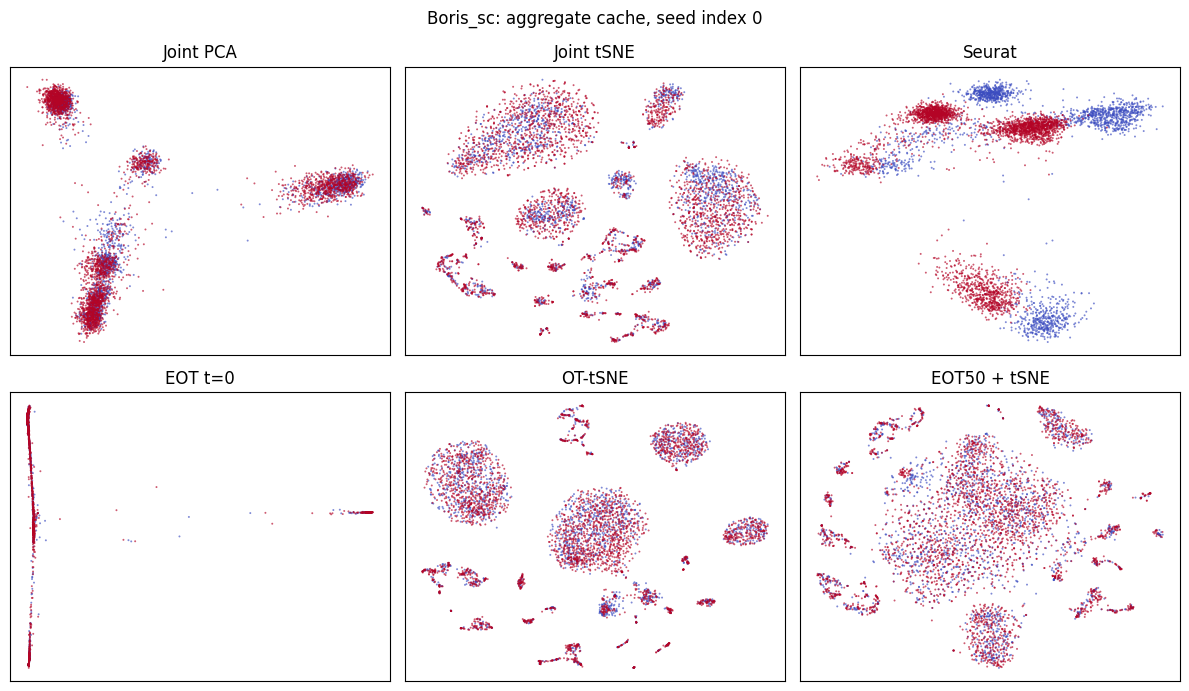

In [4]:
fig = plot_aggregate_cache_overview(CACHE_PATH, SELECTED_PATH)
plt.show()